# 4. Visualisasi Map (Folium)

Di tahap terakhir, kita memvisualisasikan kembali wilayah yang sudah kita digitasi ke dalam sebuah peta *(interactive map)*. 

Mengingat dataset berisi ratusan ribu titik piksel, me-render tiap titik satu-per-satu di peta interaktif akan membekukan (*crash*) memori browser. Solusi paling *robust* adalah menyatukan kembali titik-titik tersebut per `poligon_id` dan membuat jaring area **(Convex Hull)** luarnya, sehingga titik berubah menjadi hamparan wilayah (*Polygon*).

In [1]:
import pandas as pd
import folium
import geopandas as gpd

# Load Data
df = pd.read_csv('../../Data/UTS/piksel_s2_zaenal.csv')

# 1. Rekonstruksi Titik menjadi Geometri menggunakan GeoPandas
gdf = gpd.GeoDataFrame(
    df, geometry=gpd.points_from_xy(df.lon, df.lat), crs="EPSG:4326"
)

# Gabungkan (dissolve) berdasarkan poligon_id untuk menyatukan piksel per poligon
polygons = gdf.dissolve(by='poligon_id', aggfunc='first').reset_index()

# Ubah kumpulan titik menjadi poligon tertutup (Convex Hull) dan buang geometri kosong
polygons['geometry'] = polygons['geometry'].convex_hull
polygons = polygons[~polygons['geometry'].is_empty]

# 2. Inisiasi Peta Folium
map_center = [df['lat'].mean(), df['lon'].mean()]
m = folium.Map(
    location=map_center, 
    zoom_start=10, 
    tiles='https://mt1.google.com/vt/lyrs=m&x={x}&y={y}&z={z}', # Standard Google Maps
    attr='Google'
)

# Tambahan Opsi Peta Satelit ke LayerControl
folium.TileLayer(
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}',
    attr='Esri',
    name='Esri Satellite',
    overlay=False,
    control=True
).add_to(m)

folium.TileLayer(
    tiles='https://mt1.google.com/vt/lyrs=s&x={x}&y={y}&z={z}',
    attr='Google',
    name='Google Satellite',
    overlay=False,
    control=True
).add_to(m)

# 3. Pewarnaan Poligon Berdasarkan Klasifikasi/Label Asli
colors = {
    'Sawah': '#FFD92F',
    'Bangunan': '#E41A1C',
    'Mangrove': '#8E44AD',
    'Hutan': '#2E7D32',
    'Laut': '#0D47A1',
    'Danau': '#4FC3F7'
}

feature_groups = {}
for label in polygons['label_teks'].unique():
    label_str = str(label)
    feature_groups[label_str] = folium.FeatureGroup(name=label_str)
    m.add_child(feature_groups[label_str])

# Memplot poligon ke peta
for idx, row in polygons.iterrows():
    label_str = str(row['label_teks'])
    color = colors.get(label_str, 'black')
    
    try:
        folium.GeoJson(
            data=row['geometry'].__geo_interface__,
            style_function=lambda x, c=color: {
                'fillColor': c,
                'color': c,
                'weight': 1,
                'fillOpacity': 0.7
            },
            tooltip=f"{label_str} (Poligon ID: {row['poligon_id']})"
        ).add_to(feature_groups[label_str])
    except Exception:
        pass # Lewati apabila terdapat anomali geometri (contoh poligon berupa titik lurus)

folium.LayerControl().add_to(m)
m

### Visualisasi Prediksi Model Terbaik (KNN)

Berdasarkan tahap pemodelan sebelumnya, algoritma **K-Nearest Neighbors (KNN)** sering kali memberikan akurasi yang lebih andal untuk klasifikasi data spasial ini. 

Sebagai penutup, mari kita gunakan model KNN (dengan $K=5$) untuk memprediksi kelas dari masing-masing poligon (berdasarkan nilai rata-rata spektral piksel di dalamnya) dan memvisualisasikan hasil prediksinya ke dalam peta interaktif. Hal ini berguna untuk membandingkan apakah prediksi model selaras dengan *ground truth* (label asli).

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

# 1. Menentukan Fitur (X) dan Target (y)
fitur = ['B02', 'B03', 'B04', 'B08', 'B11', 'NDVI', 'NDWI', 'MNDWI', 'NDBI']
df_bersih = df.dropna(subset=fitur + ['label_teks']).copy()

# Ambil sampel acak berimbang per kelas (600 per kelas)
# Mempertahankan karakteristik spektral asli piksel namun memungkinkan inferensi cepat (~1 menit)
df_sample = df_bersih.groupby('label_teks', group_keys=False).apply(
    lambda x: x.sample(n=min(len(x), 600), random_state=42)
)

X_train = df_sample[fitur]
y_train = df_sample['label_teks']

# 2. Standarisasi Fitur
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# 3. Inisialisasi dan Pelatihan Model KNN (k=5)
knn_model = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
knn_model.fit(X_train_scaled, y_train)

# 4. Agregasi fitur per poligon (menggunakan rata-rata piksel)
poly_features = df_bersih.groupby('poligon_id')[fitur].mean().reset_index()
poly_features_scaled = scaler.transform(poly_features[fitur])

# Prediksi label poligon menggunakan model KNN
poly_features['prediksi_label'] = knn_model.predict(poly_features_scaled)

# Gabungkan hasil prediksi dengan geometri dan label asli poligon sebelumnya
polygons_pred = polygons[['poligon_id', 'geometry', 'label_teks']].merge(poly_features[['poligon_id', 'prediksi_label']], on='poligon_id')

# 3. Plotting ke Peta Baru (Peta Prediksi)
m_pred = folium.Map(
    location=map_center, 
    zoom_start=10, 
    tiles='https://mt1.google.com/vt/lyrs=m&x={x}&y={y}&z={z}',
    attr='Google'
)

# Tambahkan opsi satelit
folium.TileLayer(
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}',
    attr='Esri', name='Esri Satellite', overlay=False, control=True
).add_to(m_pred)

# Siapkan FeatureGroup untuk tiap kelas prediksi dan satu grup khusus "Salah Prediksi"
feature_groups_pred = {}
for label in polygons_pred['prediksi_label'].unique():
    label_str = str(label)
    feature_groups_pred[label_str] = folium.FeatureGroup(name=f"Prediksi: {label_str}")
    m_pred.add_child(feature_groups_pred[label_str])

salah_prediksi_group = folium.FeatureGroup(name="⚠️ Salah Prediksi", show=True)
m_pred.add_child(salah_prediksi_group)

# Memplot poligon dengan warna berdasarkan kelas prediksi
for idx, row in polygons_pred.iterrows():
    label_pred = str(row['prediksi_label'])
    label_asli = str(row['label_teks'])
    color = colors.get(label_pred, 'black')
    is_correct = (label_pred == label_asli)
    
    try:
        # Plot dasar (sesuai prediksi)
        folium.GeoJson(
            data=row['geometry'].__geo_interface__,
            style_function=lambda x, c=color: {
                'fillColor': c,
                'color': c,
                'weight': 1,
                'fillOpacity': 0.7
            },
            tooltip=f"Prediksi: {label_pred} | Asli: {label_asli} (ID: {row['poligon_id']})"
        ).add_to(feature_groups_pred[label_pred])

        # Plot tambahan (highlight outline merah) jika salah prediksi
        if not is_correct:
            folium.GeoJson(
                data=row['geometry'].__geo_interface__,
                style_function=lambda x: {
                    'fillColor': 'none',
                    'color': 'red',
                    'weight': 4,
                    'dashArray': '5, 5'
                },
                tooltip=f"⚠️ SALAH PREDIKSI! Asli: {label_asli}, Prediksi: {label_pred} (ID: {row['poligon_id']})"
            ).add_to(salah_prediksi_group)
    except Exception:
        pass

folium.LayerControl().add_to(m_pred)
m_pred

C:\Users\ASUS\AppData\Local\Temp\ipykernel_12800\3512364188.py:11: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_sample = df_bersih.groupby('label_teks', group_keys=False).apply(


### Visualisasi Prediksi Menyeluruh (Skala Raster Jawa Timur)

Pada peta ketiga ini, kita akan membawa model **KNN** selangkah lebih maju dengan memproyeksikannya ke seluruh citra satelit wilayah Jawa Timur (atau *sample area* yang luas), bukan lagi terbatas pada batas poligon *ground truth*. 

Karena data citra satelit mentah berupa raster berukuran besar, kita akan mengekstrak piksel-piksel raster `.tif` (terdiri dari 5 *band* yang sama), menghitung indeks spektralnya, memprediksi piksel per piksel menggunakan model klasifikasi, dan mengubahnya menjadi *layer* transparan per kelas. Melalui antarmuka Folium, Anda dapat mengaktifkan atau mematikan centang pada kelas tertentu (misal: hanya melihat "Hutan" dan "Sawah").

Untuk memperoleh citra satelit skala regional Jawa Timur, kita menggunakan layanan openEO Copernicus Data Space Ecosystem (CDSE). Skrip berikut digunakan untuk mengunduh komposit bulanan Sentinel-2 L2A (B02, B03, B04, B08, B11) dengan resolusi spasial ~250m:

```python
import os
import openeo

FILE_RASTER = '../../Data/UTS/jatim_250m.tif'

# Unduh data satelit Jawa Timur via openEO Batch Job
if not os.path.exists(FILE_RASTER):
    connection = openeo.connect("https://openeo.dataspace.copernicus.eu").authenticate_oidc()
    
    bbox_jatim = {
        "west": 110.89, "south": -8.84,
        "east": 114.63, "north": -6.65
    }
    
    cube = connection.load_collection(
        "SENTINEL2_L2A",
        spatial_extent=bbox_jatim,
        temporal_extent=["2024-08-01", "2024-08-31"],
        bands=['B02', 'B03', 'B04', 'B08', 'B11'],
        max_cloud_cover=30
    )
    
    # Agregasi waktu (Median) & resampling resolusi ke ~250 meter
    cube = cube.median_time()
    cube = cube.resample_spatial(resolution=0.0025, projection=4326)
    cube = cube.save_result(format="GTiff")
    
    # Eksekusi via Batch Job
    job = cube.create_job(title="Jatim_Composite_250m")
    job.start_and_wait()
    job.get_results().download_file(FILE_RASTER)
```

Setelah citra `jatim_250m.tif` tersedia, kita mengekstrak nilai reflektansi dari masing-masing band, menghitung indeks spektral, melakukan prediksi piksel per piksel menggunakan model **KNN**, dan menampilkannya ke dalam peta interaktif Folium:

Memprediksi tutupan lahan seluruh Jawa Timur dengan KNN...


Prediksi selesai! Membangun peta interaktif...



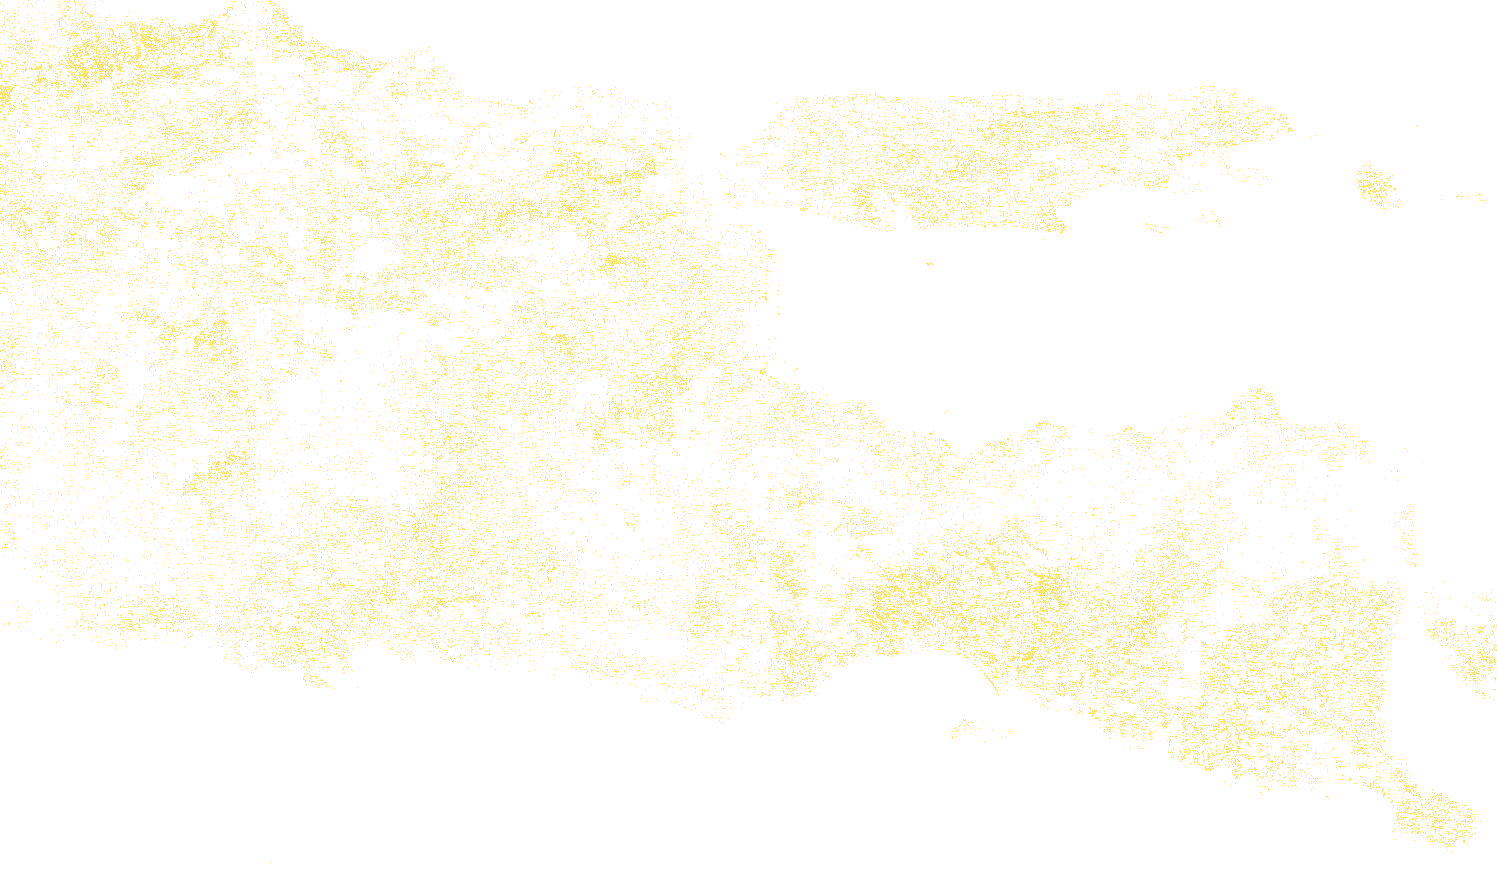
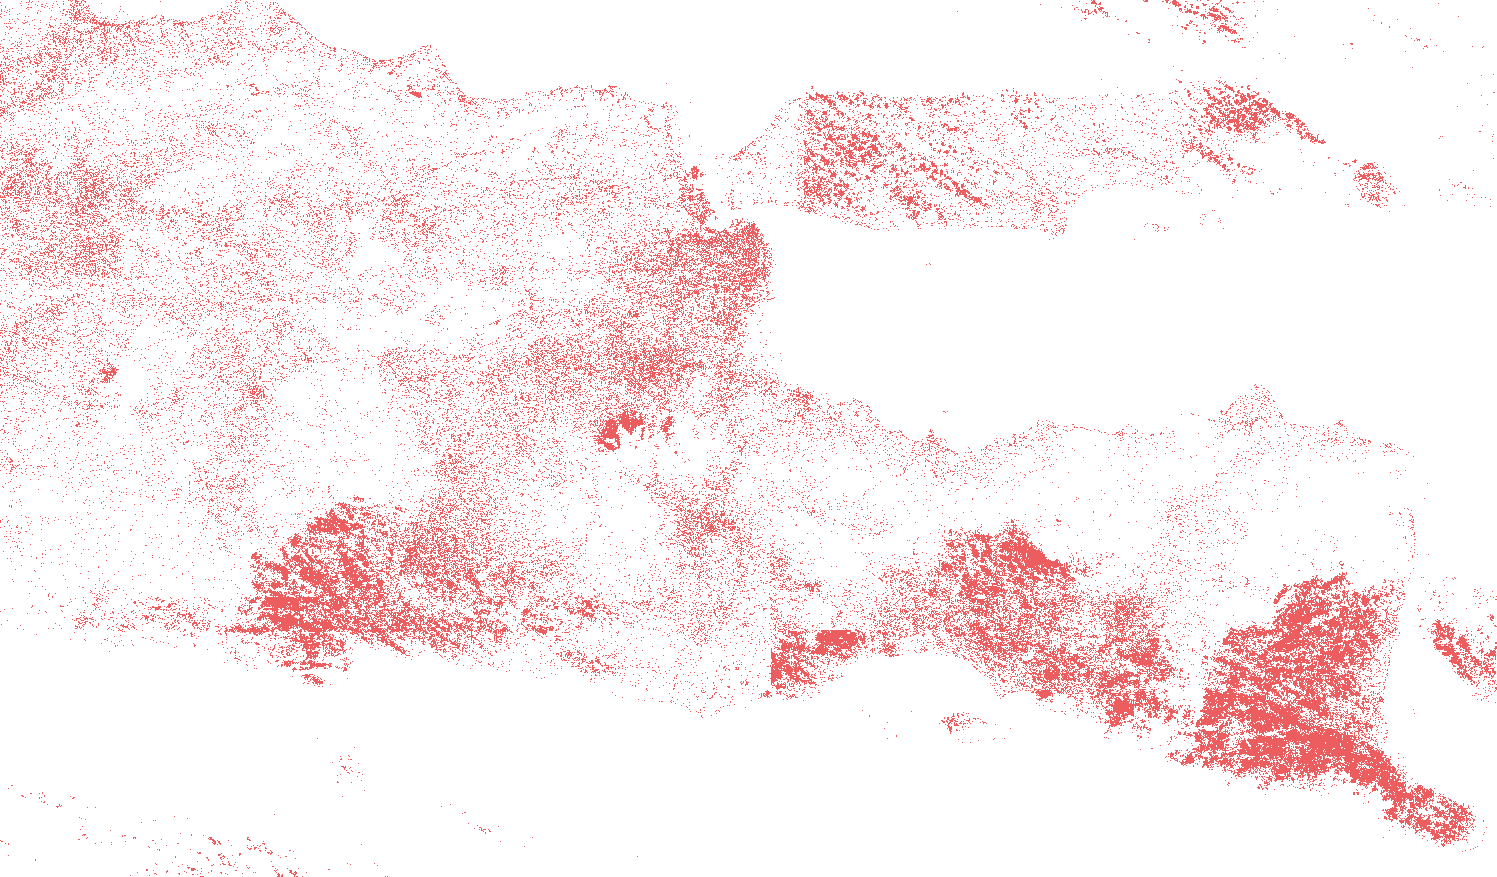
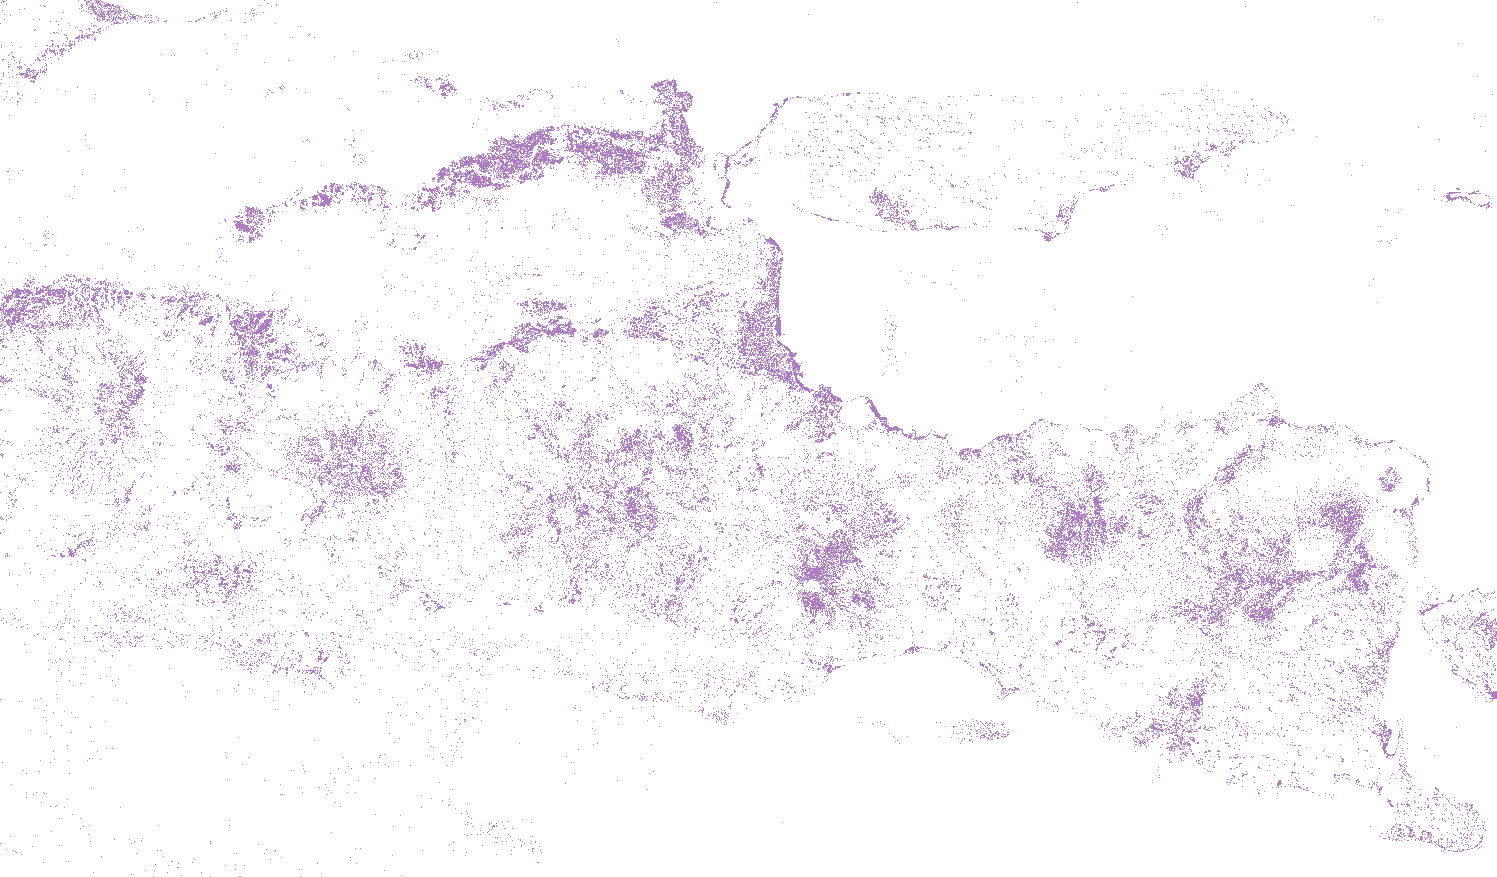
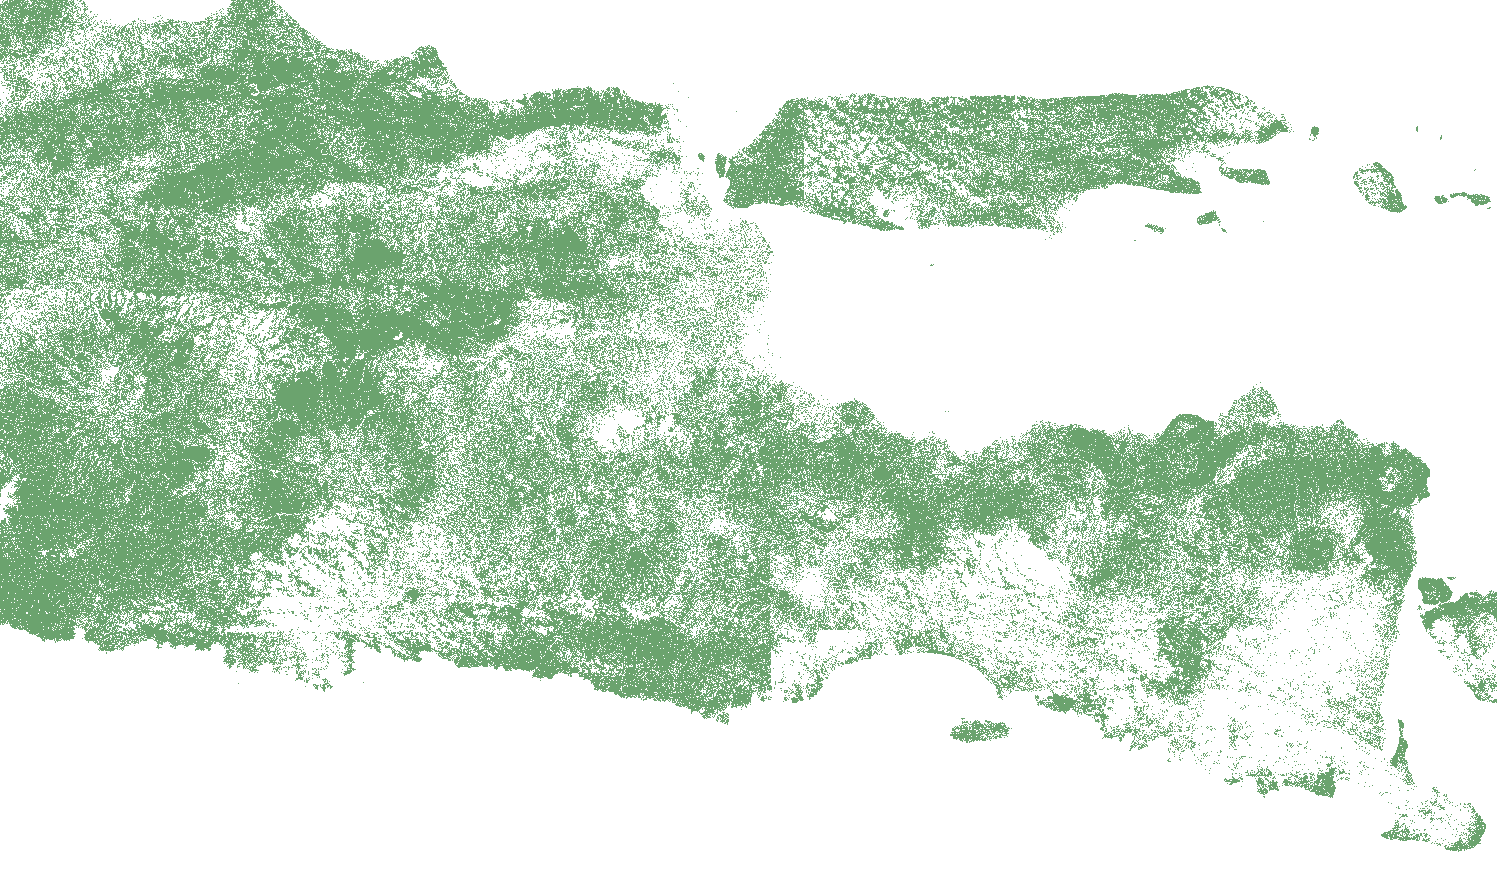
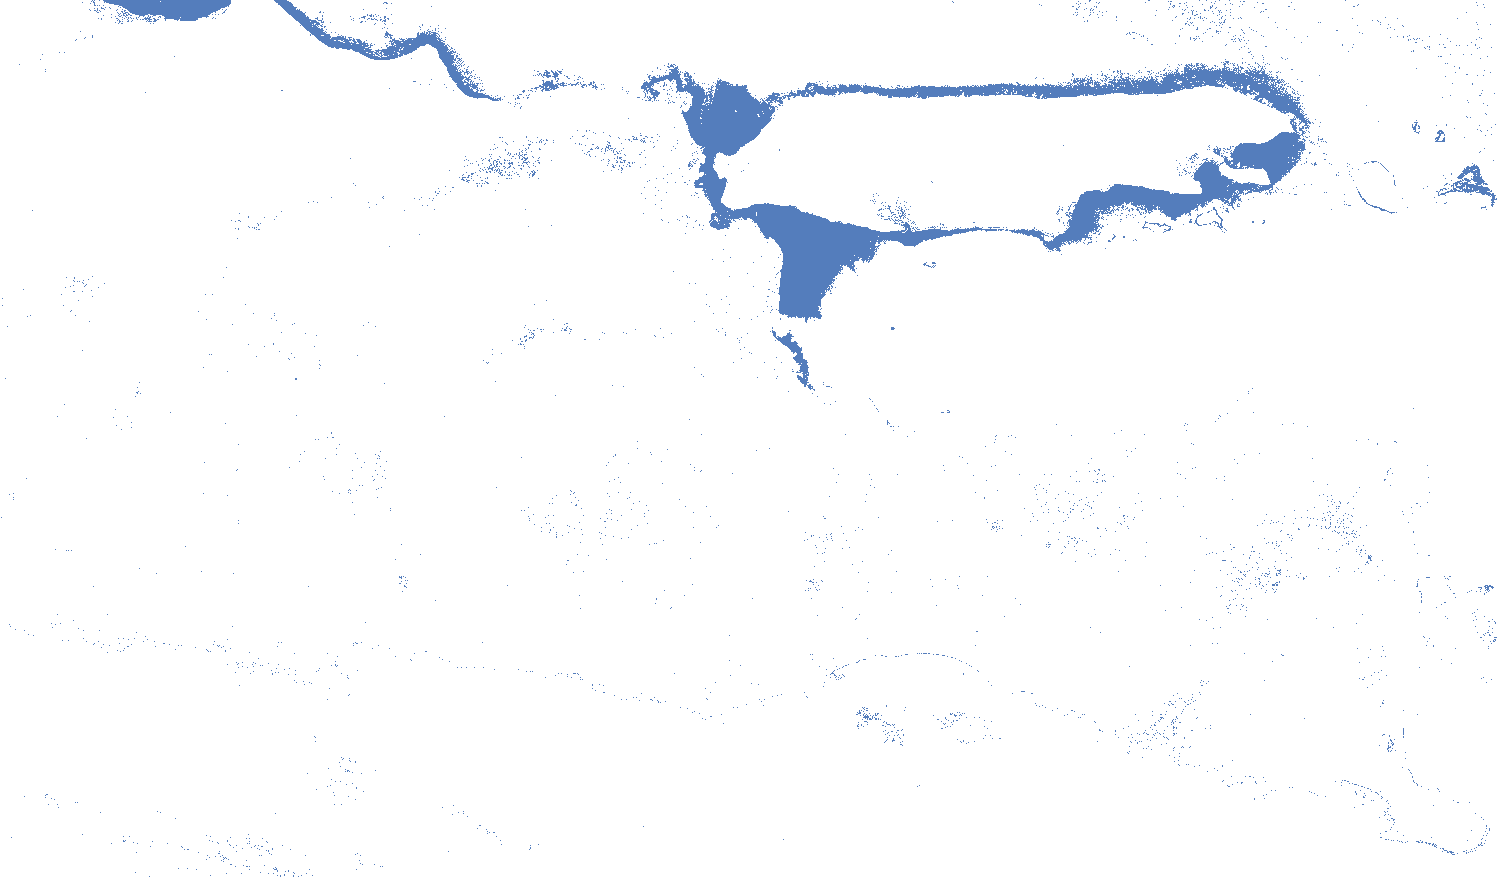
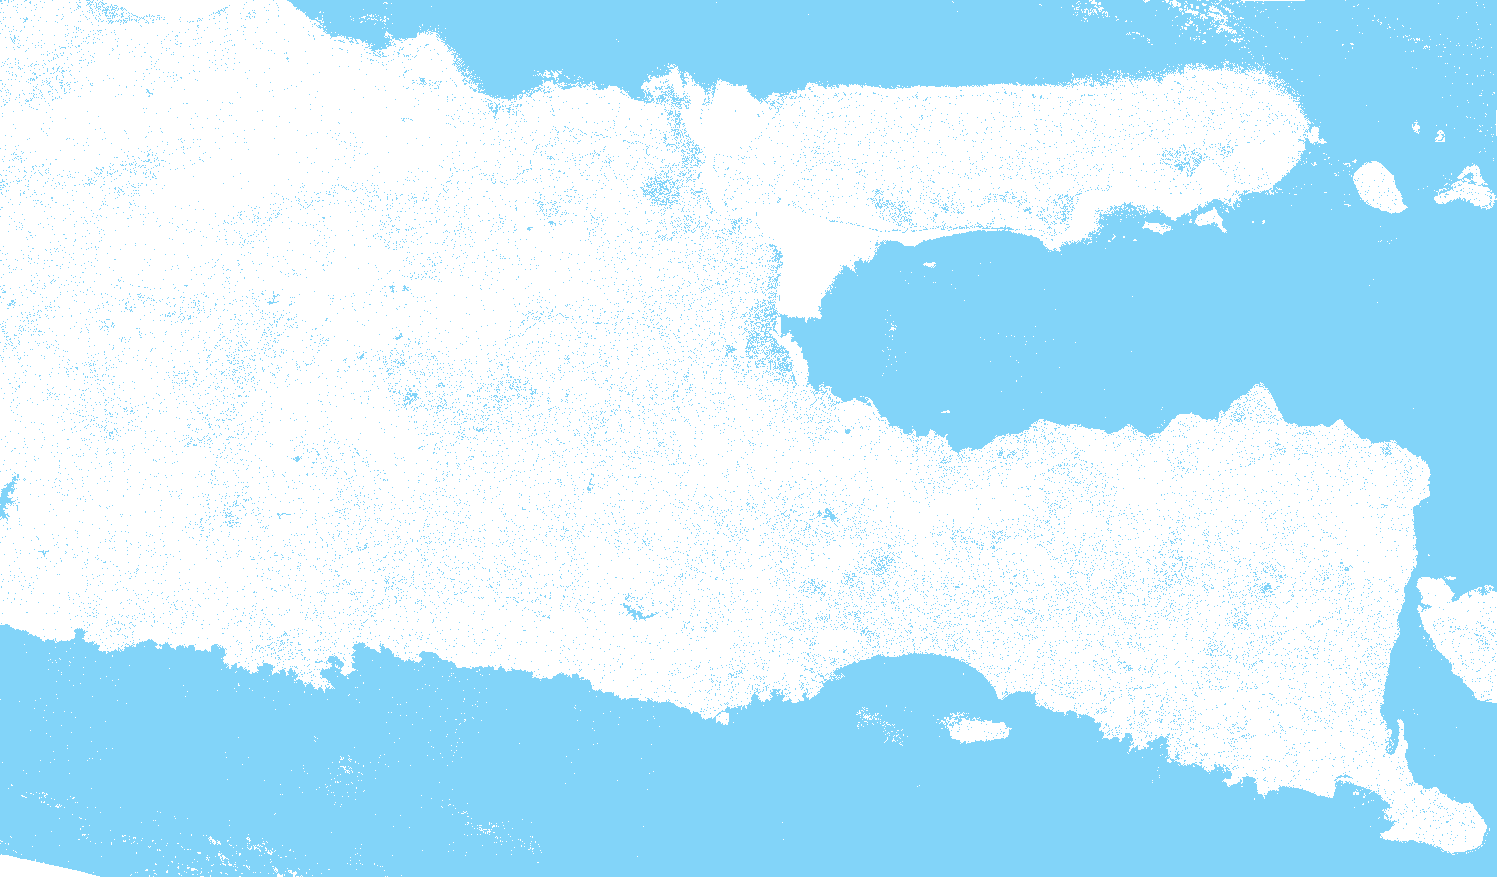

In [3]:
import os
import warnings
import rasterio
import numpy as np
import folium

warnings.filterwarnings('ignore')

# Fungsi pembantu: konversi kode warna hex (#RRGGBB) ke (R, G, B)
def hex_to_rgb(hex_code):
    hex_code = hex_code.lstrip('#')
    return tuple(int(hex_code[i:i+2], 16) for i in (0, 2, 4))

# Tentukan path raster wilayah utuh
FILE_RASTER = '../../Data/UTS/jatim_250m.tif'
if not os.path.exists(FILE_RASTER):
    for p in ['jatim_250m.tif', '../Data/UTS/jatim_250m.tif', '../../Data/UTS/jatim_250m.tif']:
        if os.path.exists(p):
            FILE_RASTER = p
            break

m_full = None

# BACA RASTER DAN LAKUKAN PREDIKSI
if os.path.exists(FILE_RASTER):
    with rasterio.open(FILE_RASTER) as src:
        # Urutan dari openEO biasanya berdasar abjad band atau urutan request: B02, B03, B04, B08, B11
        b2 = src.read(1).astype(float)
        b3 = src.read(2).astype(float)
        b4 = src.read(3).astype(float)
        b8 = src.read(4).astype(float)
        b11 = src.read(5).astype(float)
        
        bounds = src.bounds
        img_bounds = [[bounds.bottom, bounds.left], [bounds.top, bounds.right]]
        center_lat = (bounds.bottom + bounds.top) / 2
        center_lon = (bounds.left + bounds.right) / 2

    # Menghitung ulang Indeks Spektral
    e = 1e-9
    ndvi = (b8 - b4) / (b8 + b4 + e)
    ndwi = (b3 - b8) / (b3 + b8 + e)
    mndwi = (b3 - b11) / (b3 + b11 + e)
    ndbi = (b11 - b8) / (b11 + b8 + e)
    
    height, width = b2.shape
    
    import warnings
    warnings.filterwarnings('ignore')
    
    # Ratakan (flatten) array 2D menjadi 1D
    features_stack = np.column_stack((
        b2.flatten(), b3.flatten(), b4.flatten(), b8.flatten(), b11.flatten(),
        ndvi.flatten(), ndwi.flatten(), mndwi.flatten(), ndbi.flatten()
    ))
    
    # Deteksi piksel valid (bukan padding 0 dan tidak ada NaN/inf)
    valid_mask = (b2.flatten() > 0) & np.isfinite(features_stack).all(axis=1)
    
    # Lakukan scaling & prediksi langsung pada seluruh piksel valid
    pred_1d = np.full(height * width, fill_value="", dtype=object)
    if np.any(valid_mask):
        features_valid = pd.DataFrame(features_stack[valid_mask], columns=fitur)
        features_scaled = scaler.transform(features_valid)
        print("Memprediksi tutupan lahan seluruh Jawa Timur dengan KNN...")
        pred_1d[valid_mask] = knn_model.predict(features_scaled)
        print("Prediksi selesai! Membangun peta interaktif...")
        
    pred_2d = pred_1d.reshape((height, width))
    valid_2d = valid_mask.reshape((height, width))
    
    # 3. PLOTTING KE PETA FOLIUM
    m_full = folium.Map(
        location=[center_lat, center_lon], 
        zoom_start=8, 
        tiles='https://mt1.google.com/vt/lyrs=s&x={x}&y={y}&z={z}',
        attr='Google Satellite'
    )
    
    # Buat Image Overlay untuk tiap kelas (layer toggleable)
    for label_str, hex_color in colors.items():
        rgba_img = np.zeros((height, width, 4), dtype=np.uint8)
        
        # Mask: Prediksi label tsb DAN merupakan piksel valid
        mask = (pred_2d == label_str) & valid_2d
        
        if np.any(mask):
            r, g, b = hex_to_rgb(hex_color)
            rgba_img[mask, 0] = r
            rgba_img[mask, 1] = g
            rgba_img[mask, 2] = b
            rgba_img[mask, 3] = 180  # Opacity 180/255 agar satelit asli sedikit terlihat
            
            folium.raster_layers.ImageOverlay(
                image=rgba_img,
                bounds=img_bounds,
                opacity=0.7,
                name=f"Sebaran {label_str}",
                show=True
            ).add_to(m_full)
    
    folium.LayerControl().add_to(m_full)

# Menampilkan peta secara langsung ke Jupyter Book
m_full